# 02. Daily profiles

Every day of the deployment (14–30 Jul) on the same **midnight-to-midnight (UTC)** axis, so days can be compared hour by hour.
Raw data, every row plotted, nothing filtered. Axes are cropped where a few outliers would squash the rest (said in the title).

Two views per channel:
- **Overlay:** all 17 days on one plot. Colour = date, light (14 Jul) → dark (30 Jul).
- **One panel per day:** the same channel, one small plot per day, with all the other days drawn in light grey behind it.

Then two day × hour strips: which **link** sent each message, and which **mode** the autopilot was in.

Lines are broken where two readings are more than 30 min apart, so gaps in the data stay visible as gaps.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_batt"] = df.voltage_battery1_v * df.current_battery1_a     # + = charging
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # battery2 = total load
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a
df["day"] = df.t.dt.floor("D")
df["hour"] = (df.t - df.day).dt.total_seconds() / 3600          # 0-24, hours since midnight UTC

DAYS = pd.date_range("2025-07-14", "2025-07-30", freq="D", tz="UTC")
GAP_H = 0.5                                                      # break lines at gaps > 30 min

# date colour: one hue, light -> dark (sequential, the order of the days is what it shows)
DAY_CMAP = mcolors.LinearSegmentedColormap.from_list("days", plt.cm.Blues(np.linspace(0.3, 1.0, 256)))
DAY_NORM = mcolors.Normalize(0, len(DAYS) - 1)
def day_color(i):
    return DAY_CMAP(DAY_NORM(i))

LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}          # same as nb 01
LINK_NAMES = {"direct": "Starlink", "imt": "Iridium", "globalstar": "Globalstar"}
MODE_COLORS = {-1: "#c7c7c7", 0: "#7f7f7f", 10: "#2ca02c", 16: "#9467bd", 17: "#d62728"}   # MANUAL split by arming (-1 = disarmed)
MODE_NAMES = {-1: "MANUAL disarmed", 0: "MANUAL armed", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
df["mode_arm"] = np.where((df.custom_mode == 0) & (df.custom0_arming == 0), -1, df.custom_mode)

def with_gaps(g, col):
    """x (hour), y with a NaN inserted wherever readings are more than GAP_H apart."""
    g = g.dropna(subset=[col])
    x, y = g.hour.to_numpy(), g[col].to_numpy()
    cut = np.where(np.diff(x) > GAP_H)[0] + 1
    return np.insert(x, cut, np.nan), np.insert(y, cut, np.nan)

def hour_axis(ax):
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])

def channel(col, links=("direct", "imt")):
    return df[df.communication_mode.isin(links) & df[col].notna()]

def overlay(col, title, ylabel, links=("direct", "imt"), ylim=None, dots=False):
    """All days on one 0-24 h axis, coloured by date."""
    d = channel(col, links)
    fig, ax = plt.subplots(figsize=(14, 5))
    for i, day in enumerate(DAYS):
        g = d[d.day == day]
        if dots:
            ax.plot(g.hour, g[col], ".", ms=1.5, color=day_color(i))
        else:
            ax.plot(*with_gaps(g, col), lw=0.9, color=day_color(i))
    sm = plt.cm.ScalarMappable(cmap=DAY_CMAP, norm=DAY_NORM)
    cb = fig.colorbar(sm, ax=ax, pad=0.01)
    cb.set_ticks(range(0, len(DAYS), 2), labels=[f"{d:%d %b}" for d in DAYS[::2]])
    cb.set_label("day")
    hour_axis(ax); ax.set_xlabel("time of day (UTC)"); ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)
    ax.set_title(title)
    plt.tight_layout(); plt.show()

def per_day(col, title, ylabel, links=("direct", "imt"), ylim=None, dots=False):
    """One small panel per day; the other days in light grey behind it. Shared axes."""
    d = channel(col, links)
    fig, axes = plt.subplots(6, 3, figsize=(14, 16), sharex=True, sharey=True)
    axes = axes.ravel()
    for i, day in enumerate(DAYS):
        ax = axes[i]
        for other in DAYS:
            if other != day:
                g = d[d.day == other]
                if dots:
                    ax.plot(g.hour, g[col], ".", ms=0.8, color="0.88")
                else:
                    ax.plot(*with_gaps(g, col), lw=0.6, color="0.88")
        g = d[d.day == day]
        if dots:
            ax.plot(g.hour, g[col], ".", ms=1.5, color="#08306b")
        else:
            ax.plot(*with_gaps(g, col), lw=1.0, color="#08306b")
        ax.set_title(f"{day:%a %d %b} ({len(g)} readings)", fontsize=9)
        hour_axis(ax); ax.tick_params(labelsize=8)
        if ylim: ax.set_ylim(*ylim)
    axes[-1].axis("off")                                         # 17 days, 18 panels
    for ax in axes[::3]: ax.set_ylabel(ylabel, fontsize=9)
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

def strip(col, colors, names, title):
    """Day x hour: one tick per message, coloured by category (link or mode)."""
    fig, ax = plt.subplots(figsize=(14, 7))
    d = df[df[col].notna()]
    for i, day in enumerate(DAYS):
        g = d[d.day == day]
        for key, c in colors.items():
            h = g[g[col] == key]
            ax.plot(h.hour, np.full(len(h), i), "|", ms=9, mew=0.8, color=c)
    no = df[df[col].isna()]                                     # rows with no value for this column
    for i, day in enumerate(DAYS):
        h = no[no.day == day]
        ax.plot(h.hour, np.full(len(h), i), "|", ms=9, mew=0.8, color="k")
    ax.set_yticks(range(len(DAYS)), [f"{d:%a %d %b}" for d in DAYS])
    ax.set_ylim(len(DAYS) - 0.5, -0.5)                          # 14 Jul at the top
    hour_axis(ax); ax.set_xlabel("time of day (UTC)"); ax.grid(axis="y", alpha=0)
    handles = [plt.Line2D([], [], marker="|", ls="", ms=10, mew=2, color=c, label=names[k]) for k, c in colors.items()]
    if len(no):
        handles.append(plt.Line2D([], [], marker="|", ls="", ms=10, mew=2, color="k", label=f"not reported ({len(no)} rows)"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    ax.set_title(title)
    plt.tight_layout(); plt.show()

df.groupby("day").size().rename("rows").to_frame().T

day,2025-07-14 00:00:00+00:00,2025-07-15 00:00:00+00:00,2025-07-16 00:00:00+00:00,2025-07-17 00:00:00+00:00,2025-07-18 00:00:00+00:00,2025-07-19 00:00:00+00:00,2025-07-20 00:00:00+00:00,2025-07-21 00:00:00+00:00,2025-07-22 00:00:00+00:00,2025-07-23 00:00:00+00:00,2025-07-24 00:00:00+00:00,2025-07-25 00:00:00+00:00,2025-07-26 00:00:00+00:00,2025-07-27 00:00:00+00:00,2025-07-28 00:00:00+00:00,2025-07-29 00:00:00+00:00,2025-07-30 00:00:00+00:00
rows,9951,1727,1704,678,715,697,959,817,961,1031,866,1417,1518,370,683,292,288


## 1. Battery voltage
Both links (Starlink and Iridium). Globalstar has no voltage.

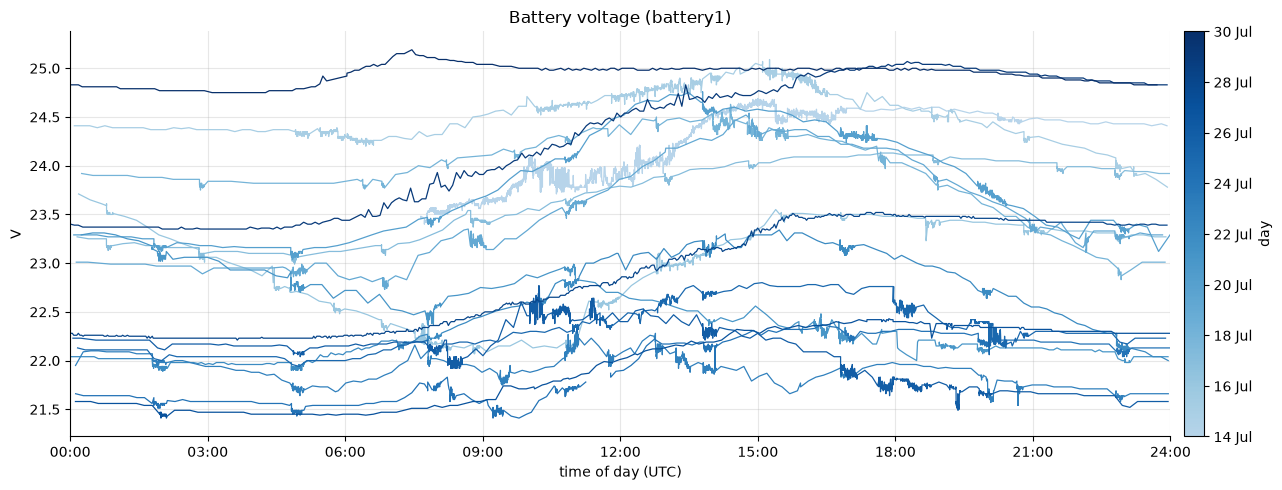

In [2]:
overlay('voltage_battery1_v', 'Battery voltage (battery1)', 'V')

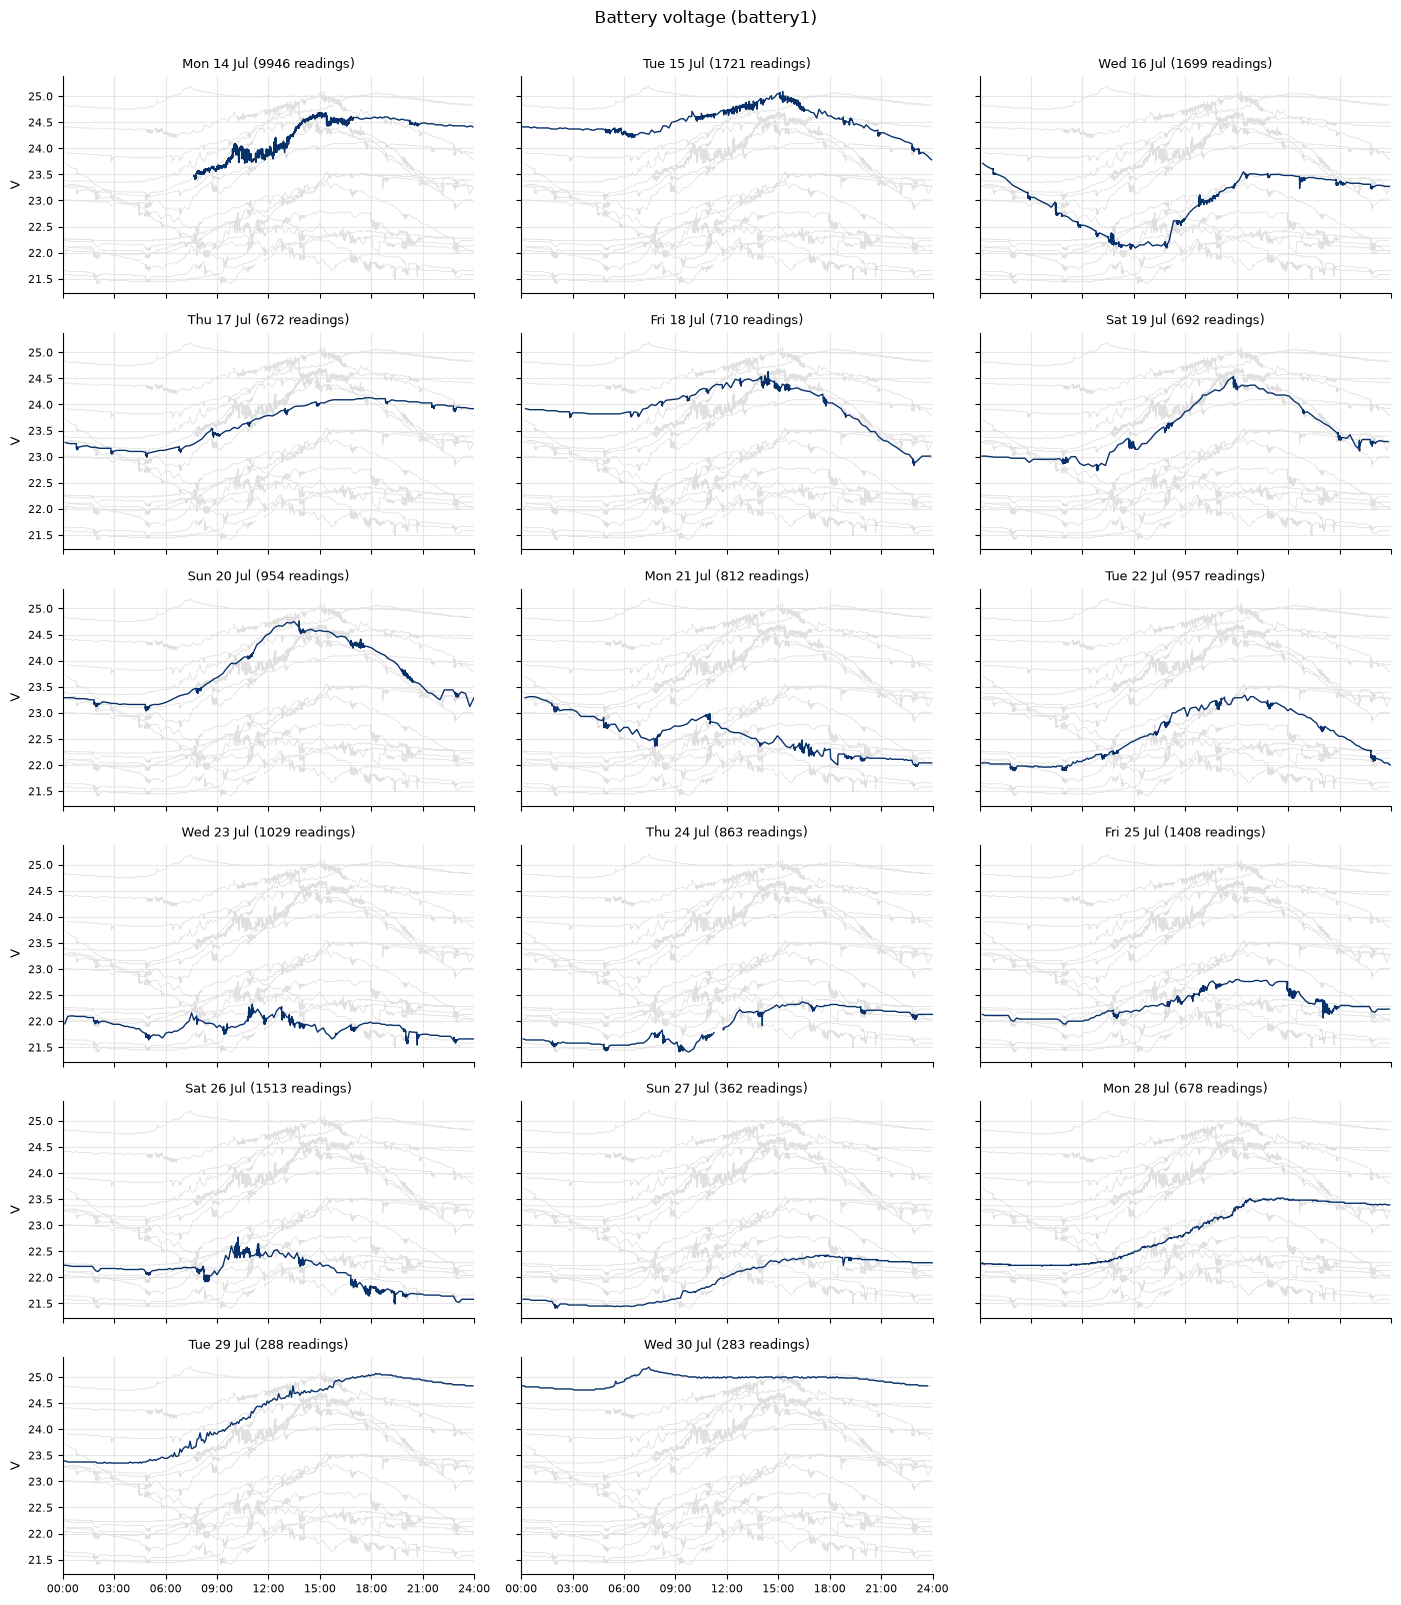

In [3]:
per_day('voltage_battery1_v', 'Battery voltage (battery1)', 'V')

## 2. Solar power
Starlink only: Iridium doesn't carry solar, so there's nothing after 27 Jul 02:05.

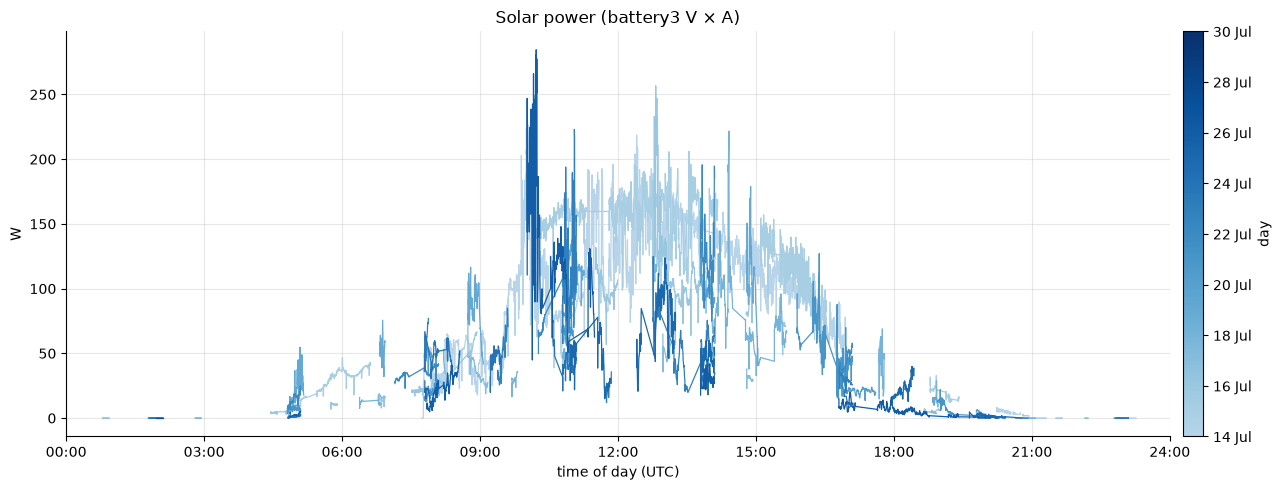

In [4]:
overlay('P_solar', 'Solar power (battery3 V × A)', 'W', links=('direct',))

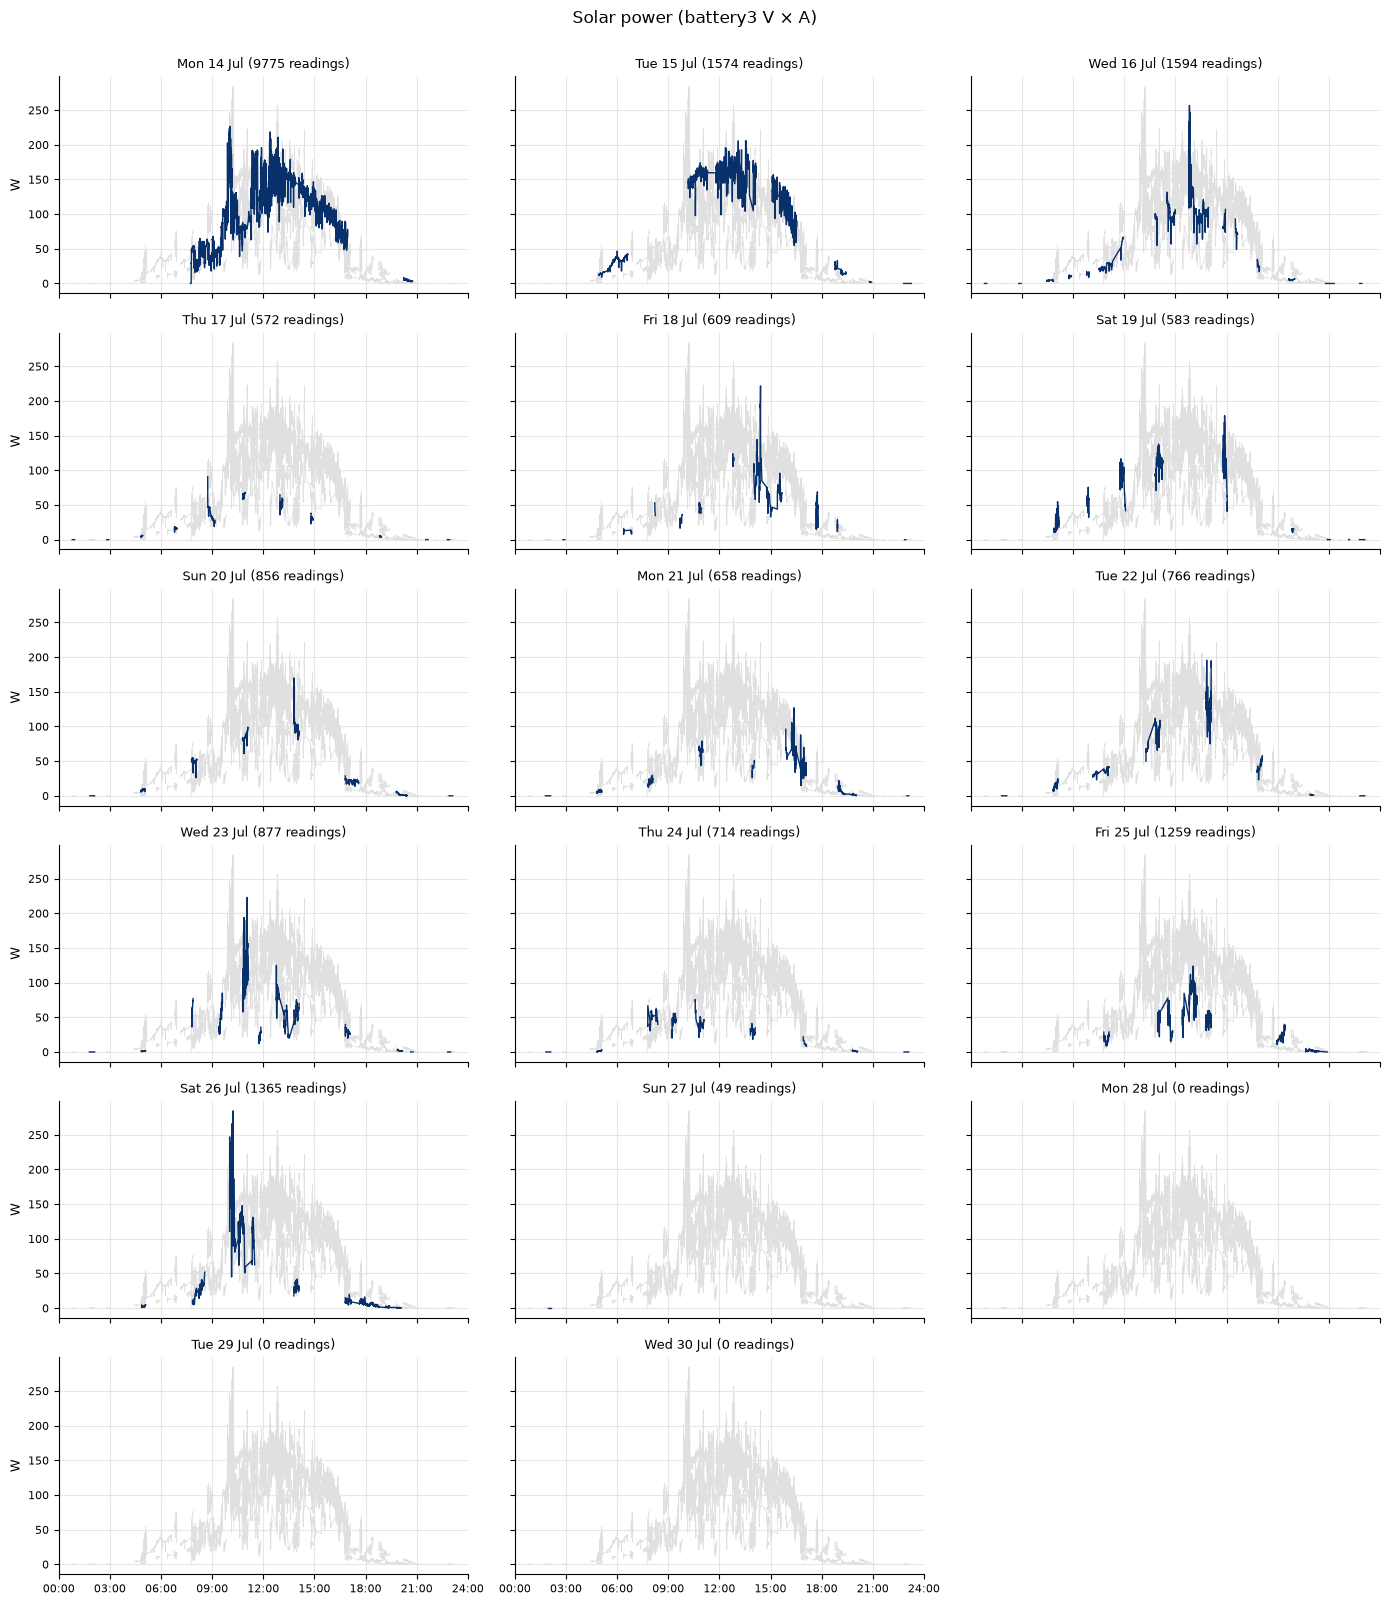

In [5]:
per_day('P_solar', 'Solar power (battery3 V × A)', 'W', links=('direct',))

## 3. Load power
Both links. battery2 is the total system load (hotel + Starlink + motor).

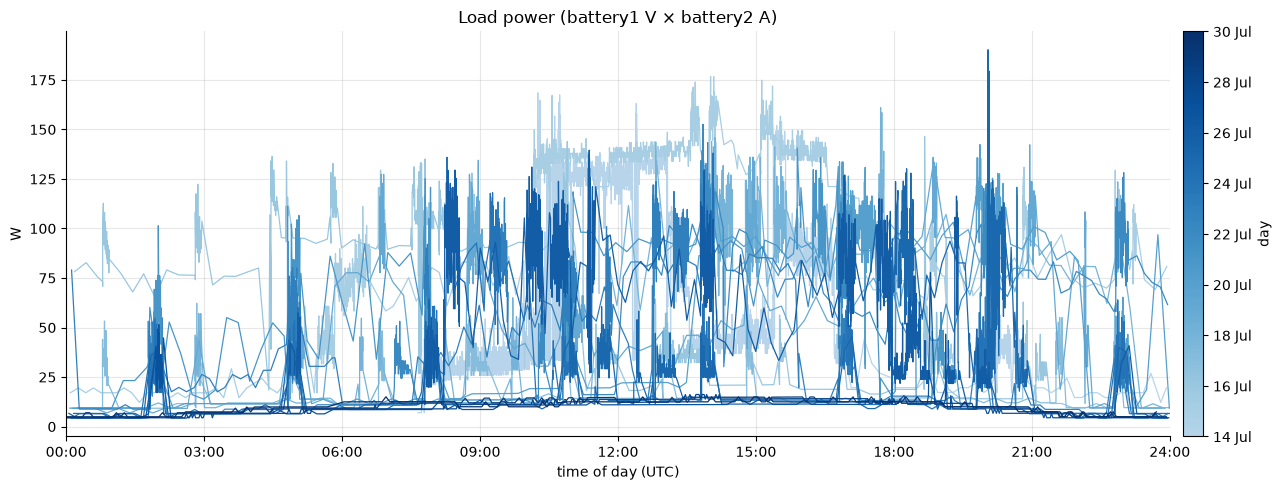

In [6]:
overlay('P_load', 'Load power (battery1 V × battery2 A)', 'W')

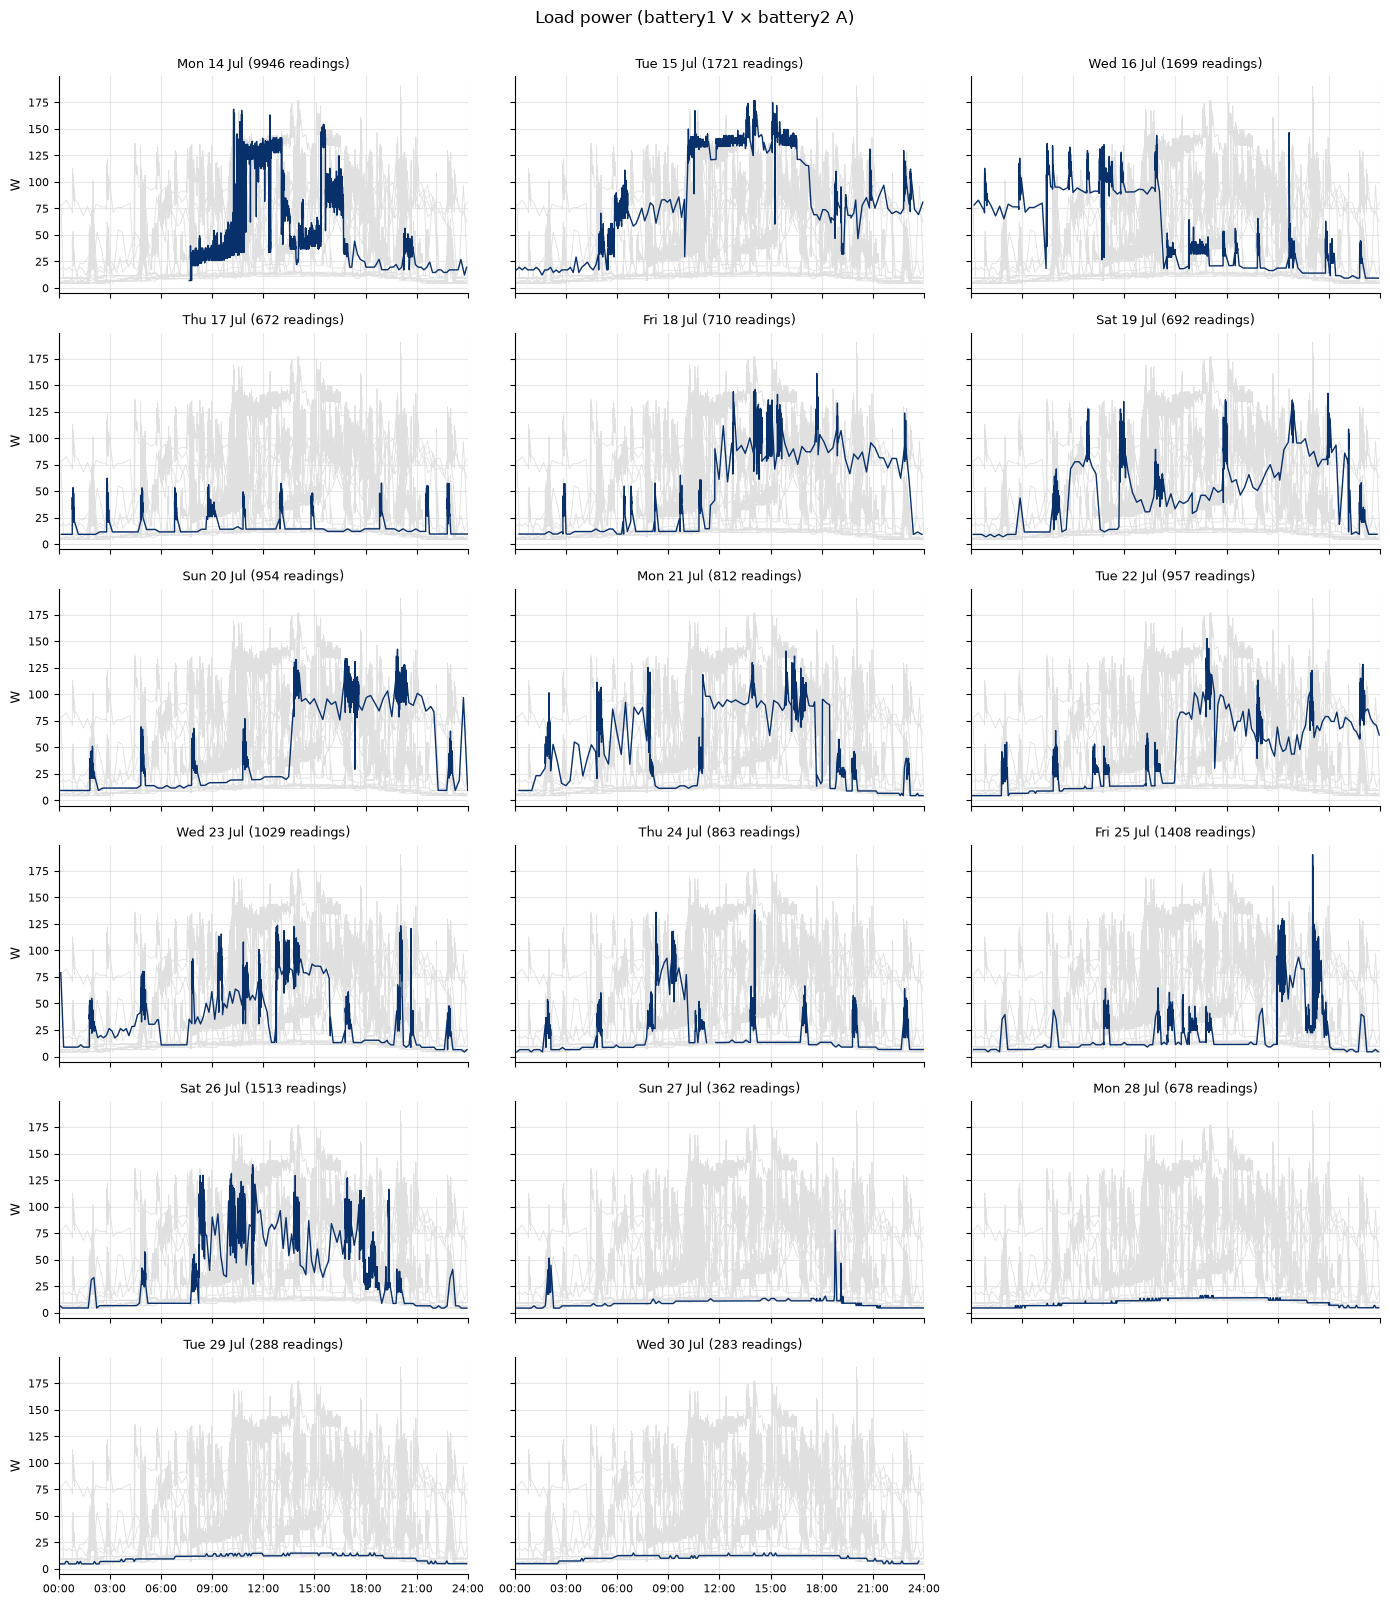

In [7]:
per_day('P_load', 'Load power (battery1 V × battery2 A)', 'W')

## 4. Battery power
Starlink only (Iridium has no battery current).

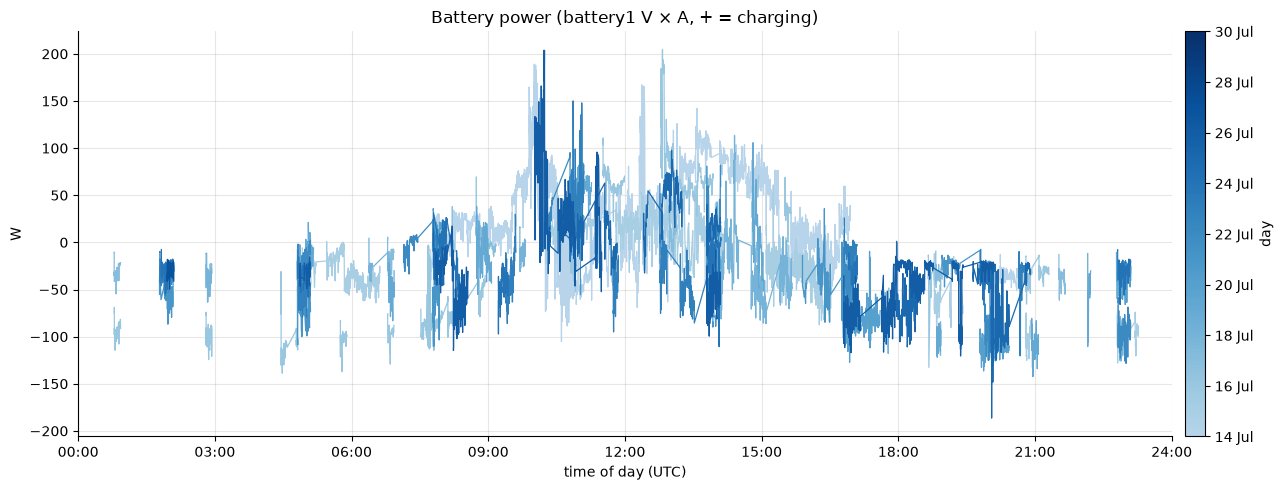

In [8]:
overlay('P_batt', 'Battery power (battery1 V × A, + = charging)', 'W', links=('direct',))

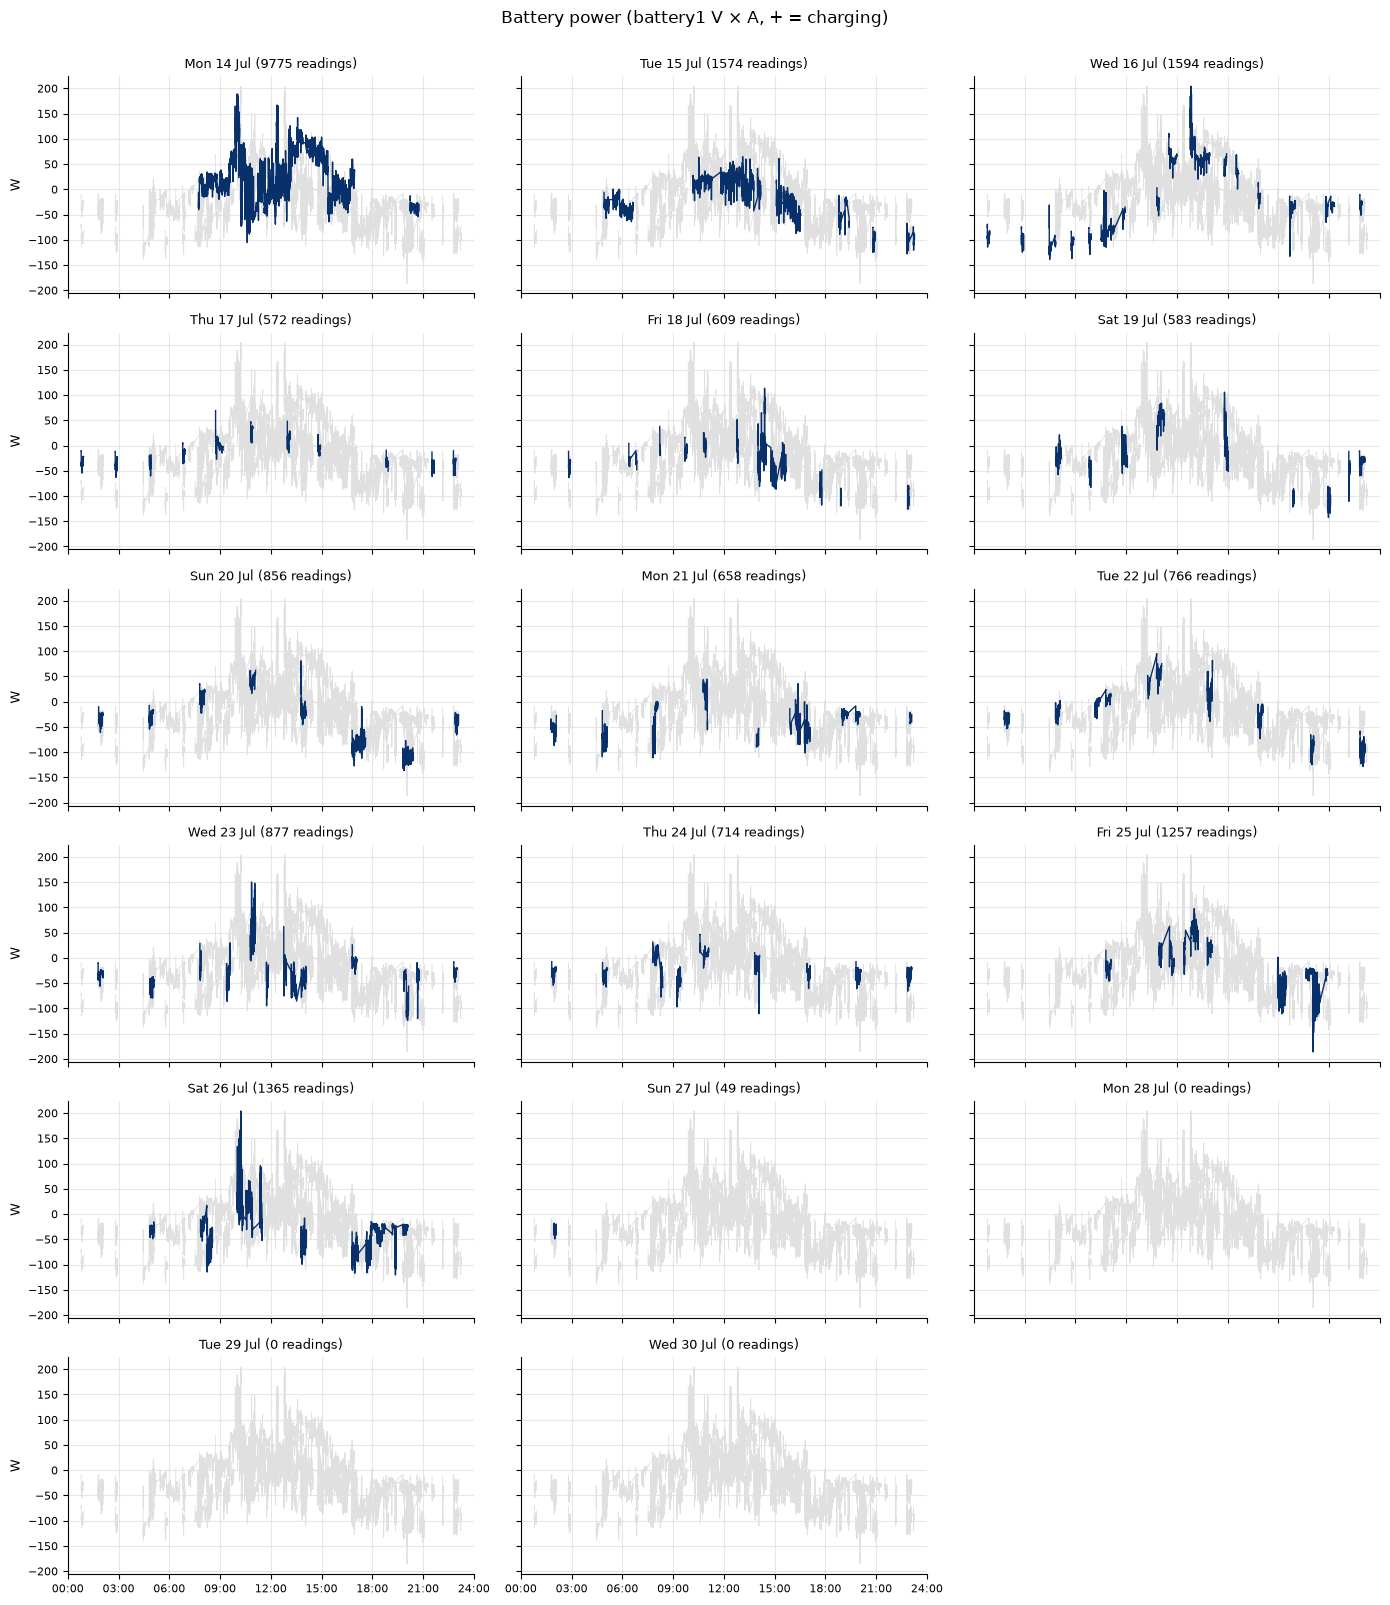

In [9]:
per_day('P_batt', 'Battery power (battery1 V × A, + = charging)', 'W', links=('direct',))

## 5. Speed over ground
Both links. Drawn as dots, not lines: speed jumps a lot from reading to reading.

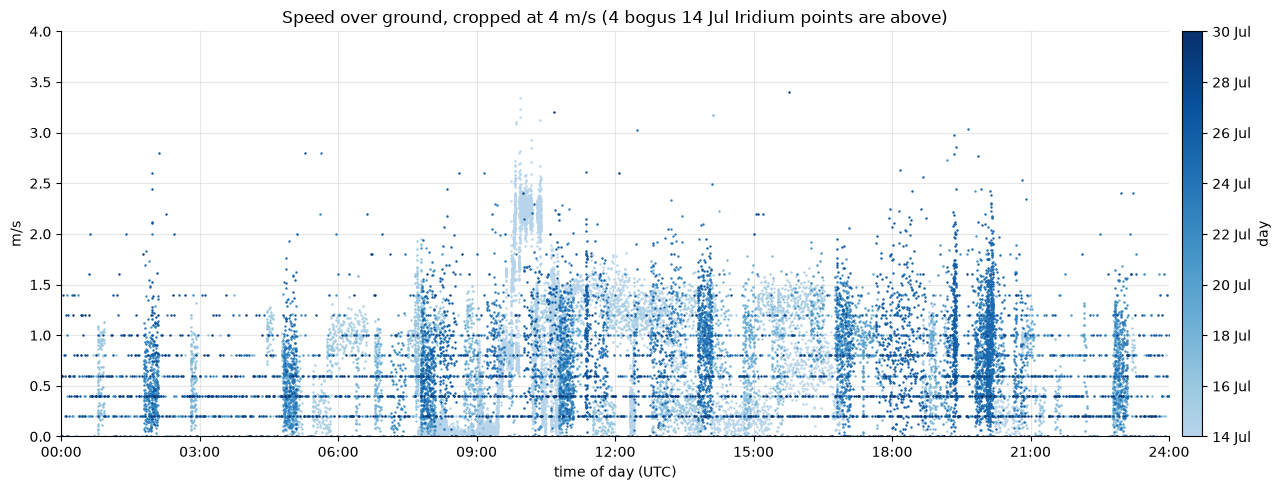

In [10]:
overlay('groundspeed_ms', 'Speed over ground, cropped at 4 m/s (4 bogus 14 Jul Iridium points are above)', 'm/s', ylim=(0, 4), dots=True)

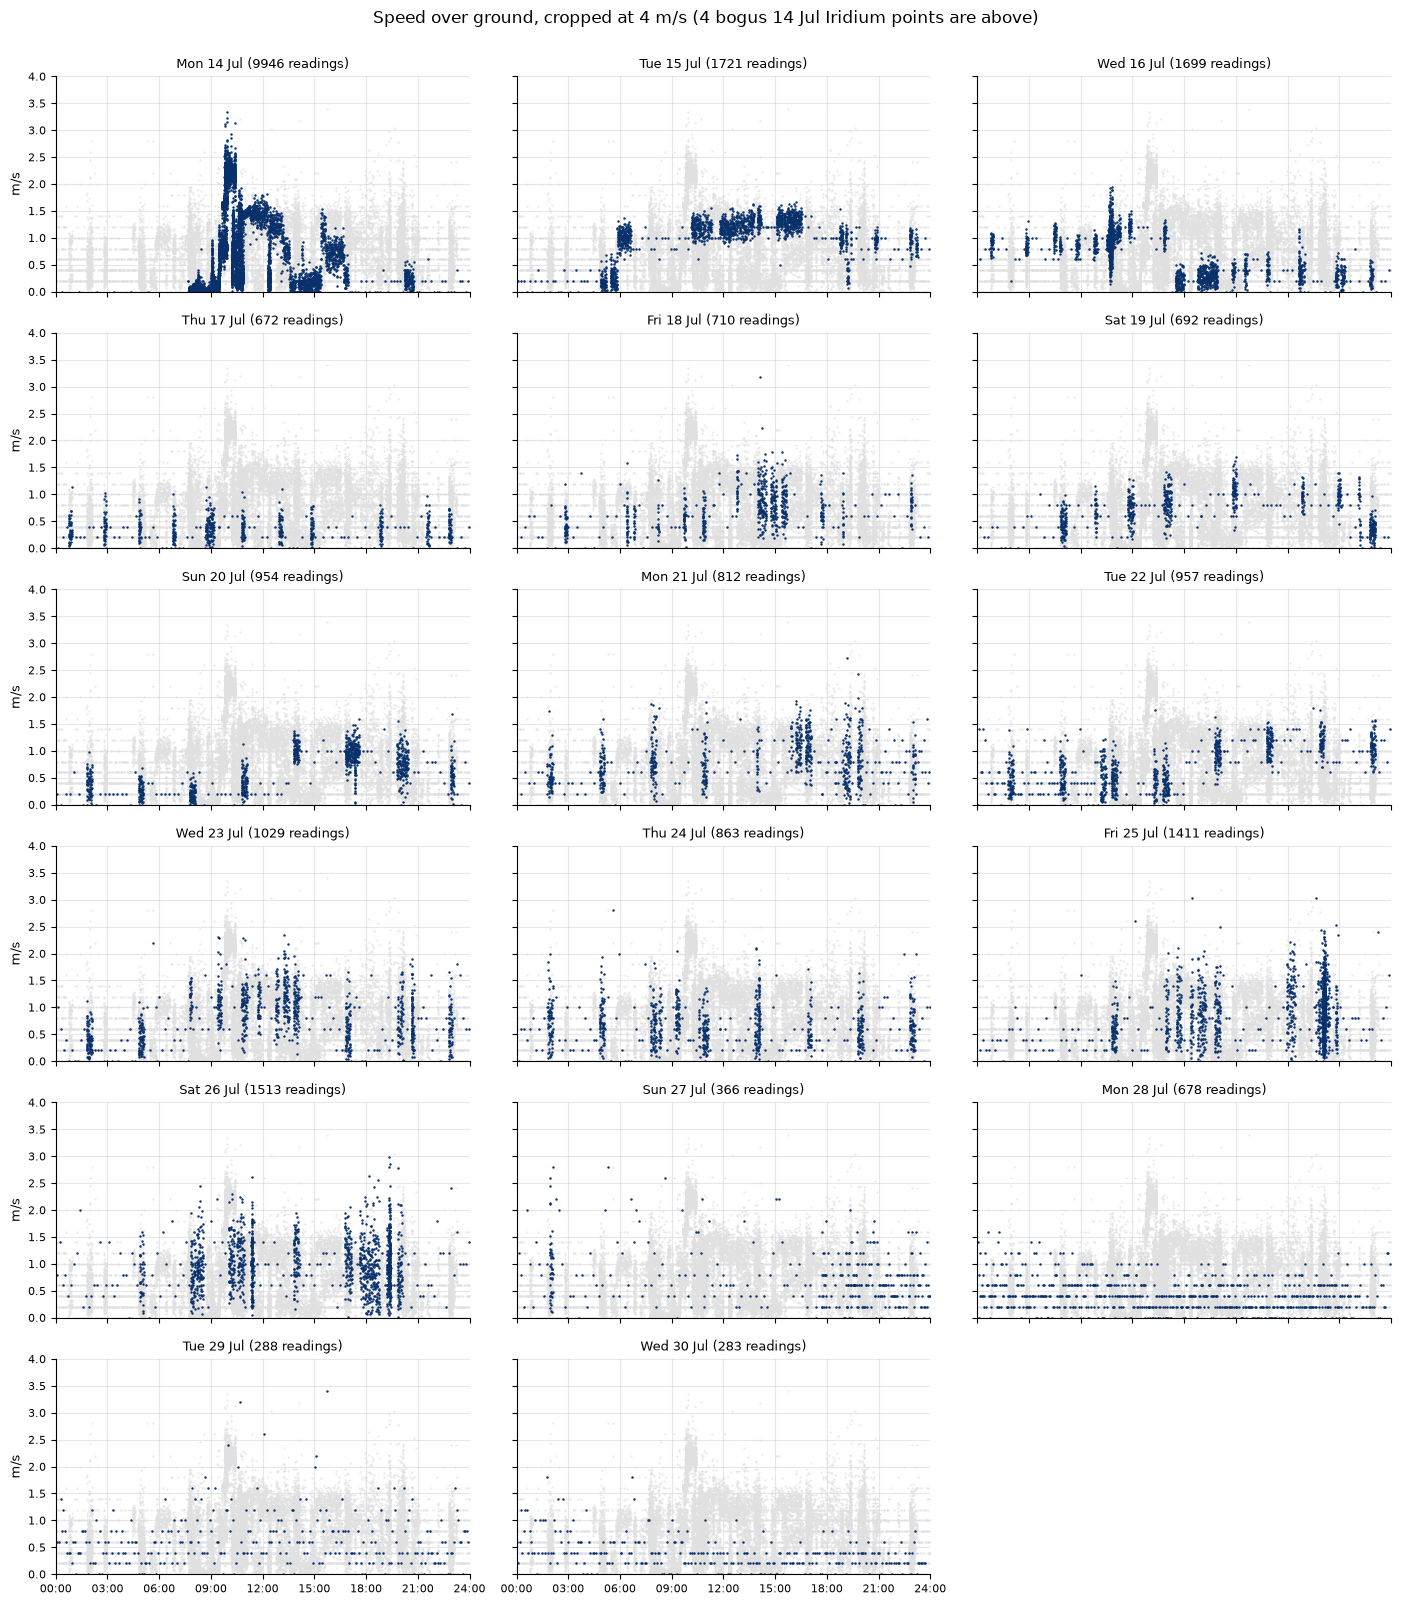

In [11]:
per_day('groundspeed_ms', 'Speed over ground, cropped at 4 m/s (4 bogus 14 Jul Iridium points are above)', 'm/s', ylim=(0, 4), dots=True)

## 6. Internal temperature
Starlink only.

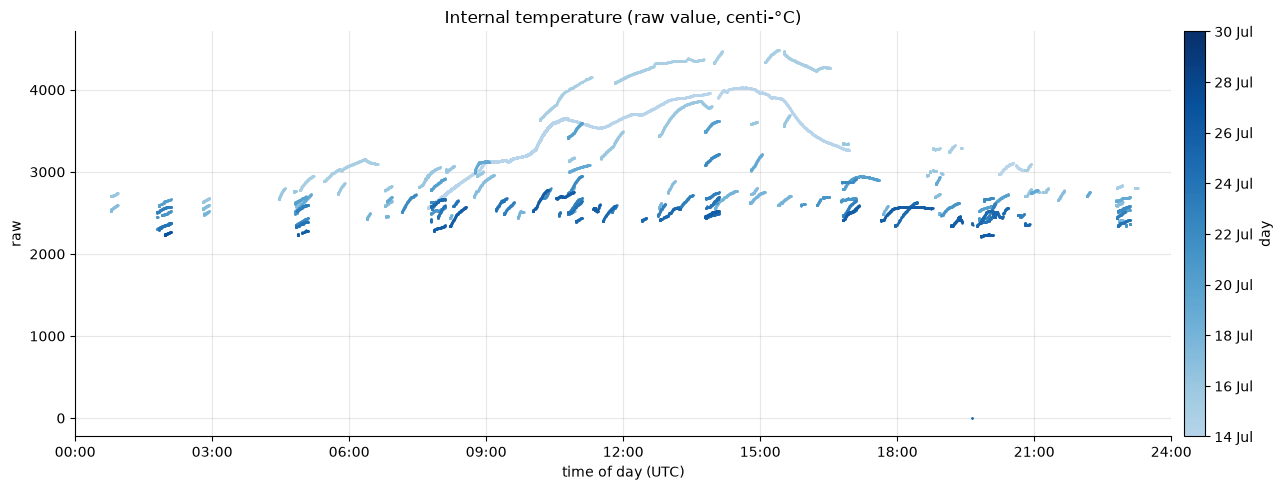

In [12]:
overlay('temperature_c', 'Internal temperature (raw value, centi-°C)', 'raw', links=('direct',), dots=True)

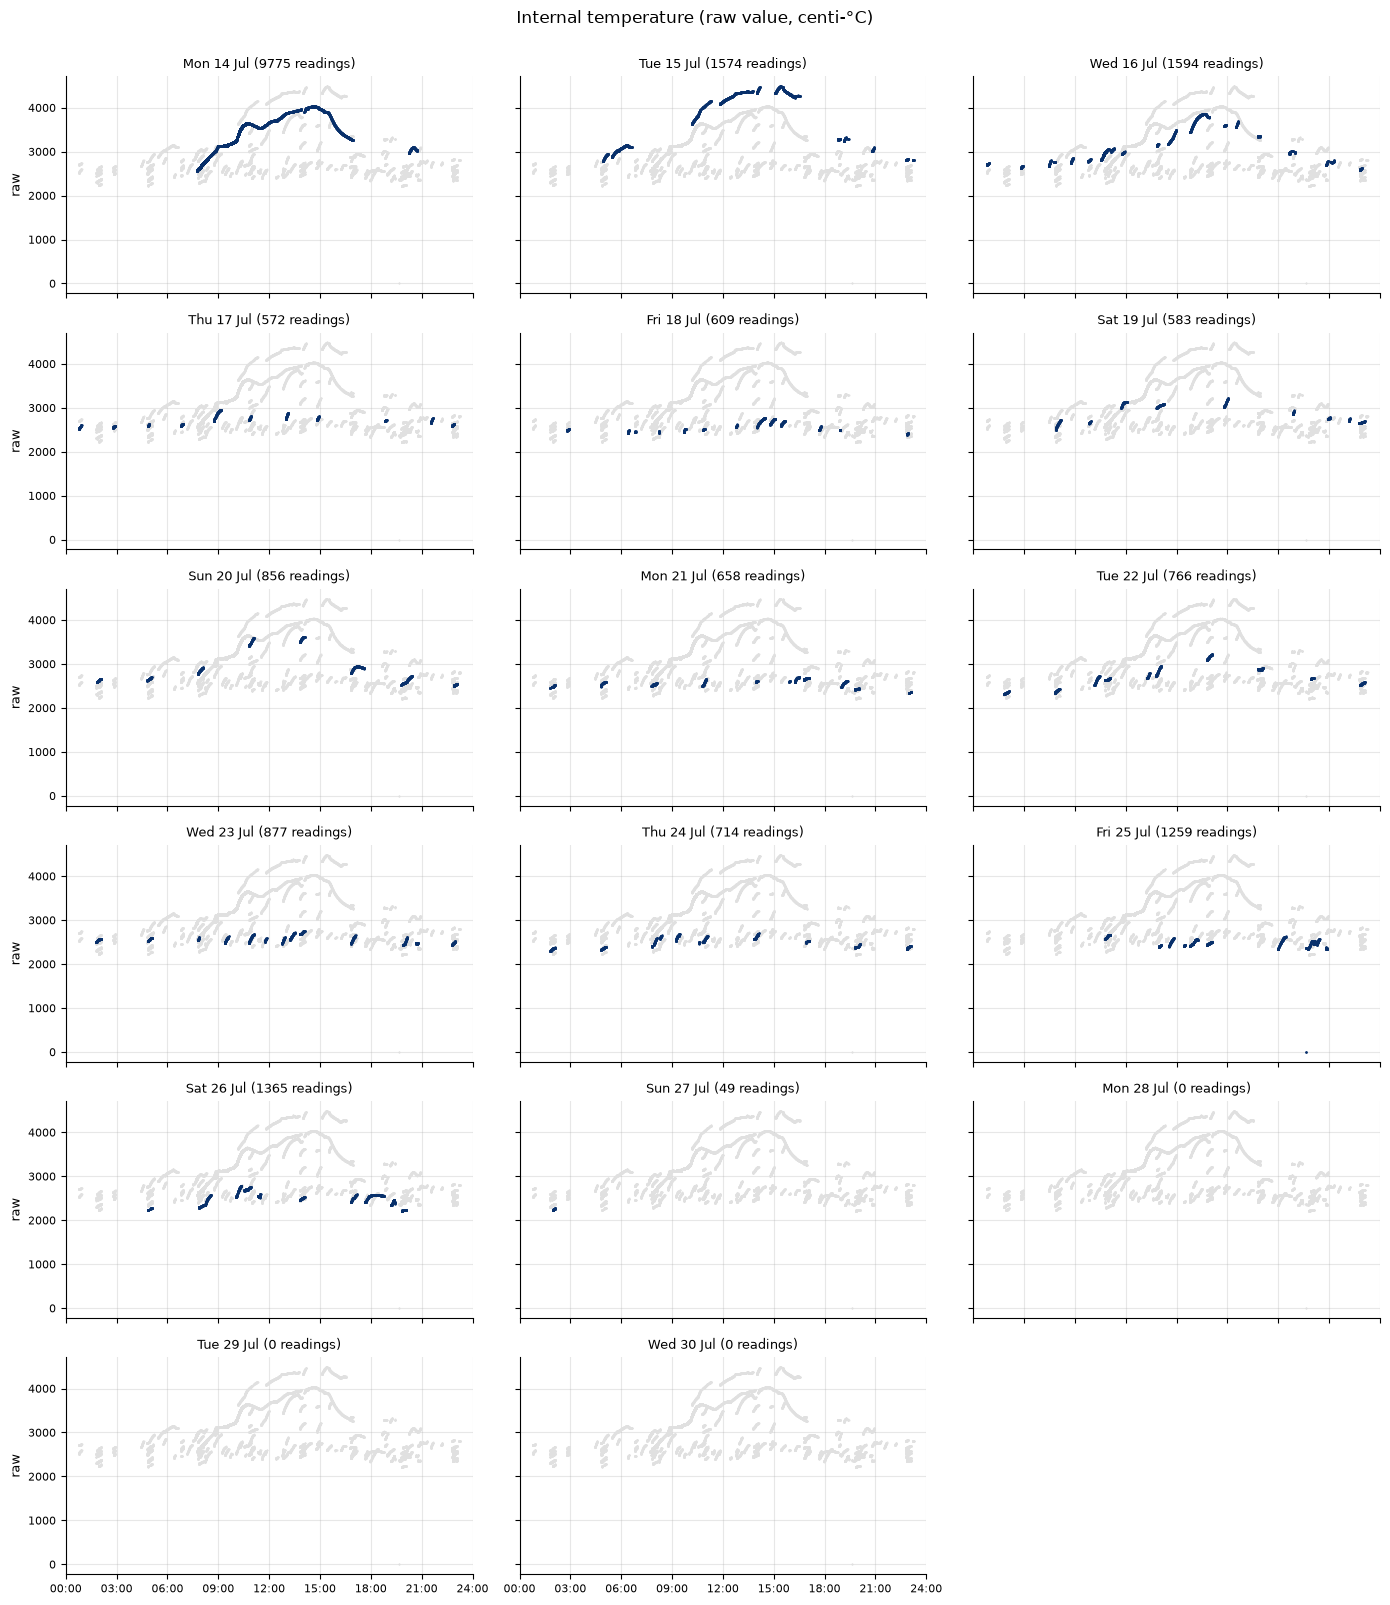

In [13]:
per_day('temperature_c', 'Internal temperature (raw value, centi-°C)', 'raw', links=('direct',), dots=True)

## 7. Which link sent each message
One tick per message. Starlink, Iridium and Globalstar.

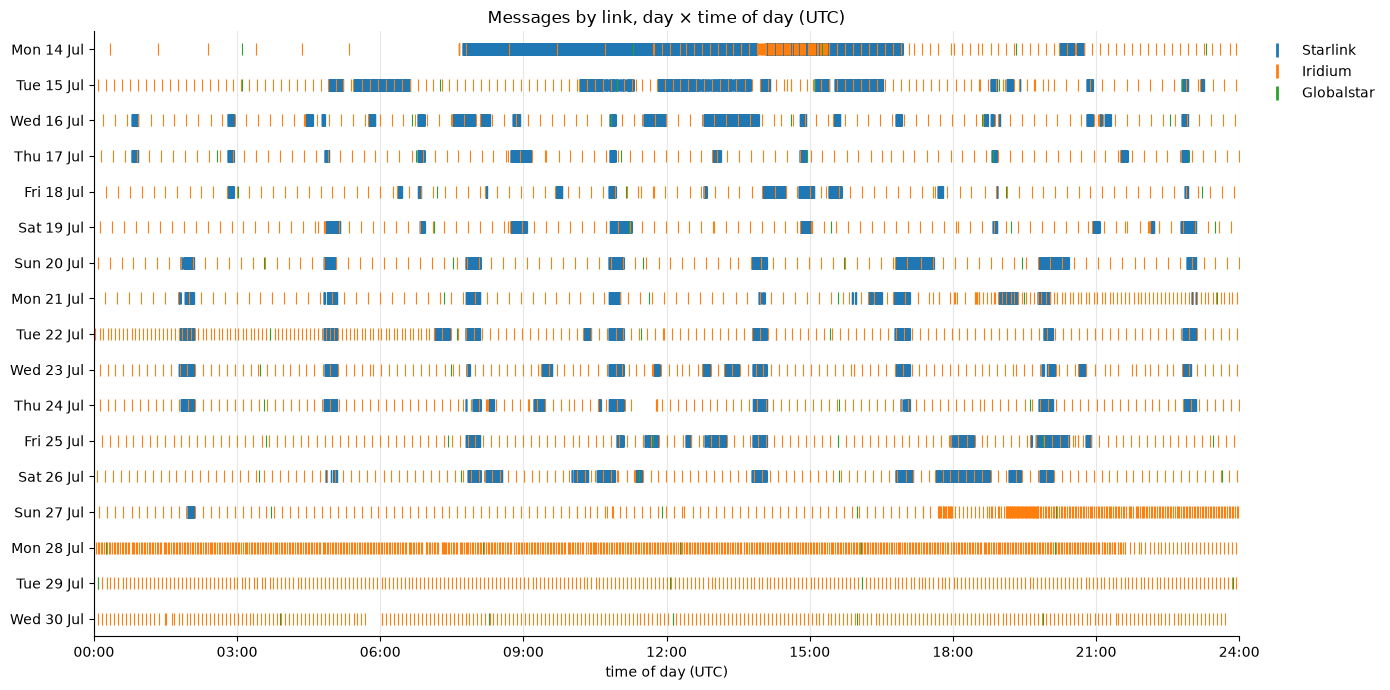

In [14]:
strip("communication_mode", LINK_COLORS, LINK_NAMES, "Messages by link, day × time of day (UTC)")

## 8. Autopilot mode
One tick per message that reports a mode (`custom_mode`). MANUAL is split by arming (`custom0_arming`); AUTO and mode 17 have only 1 disarmed message each, so they aren't split. Globalstar rows have no mode: they're the black ticks.

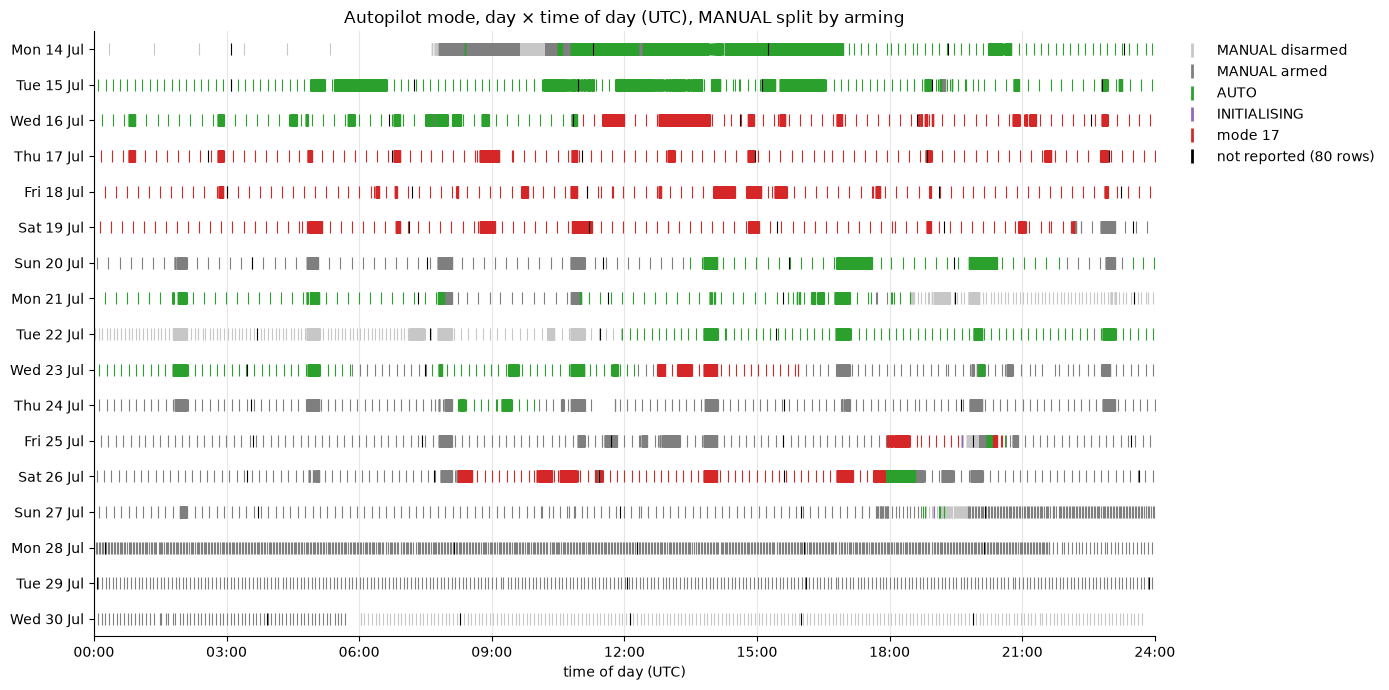

In [15]:
strip("mode_arm", MODE_COLORS, MODE_NAMES, "Autopilot mode, day × time of day (UTC), MANUAL split by arming")